# Fast search, complete construction, measured outcomes

The inner decoder problem has a finite grammar. The outer problem chooses
ownership, compute, transport and lifetime together.

**Evidence:** recorded H200 summaries and complete-program campaign ledgers,
replayed on CPU. The production CUDA enumerator and MCTS engine are not run here.
[Method and scope](../docs/studies.md#structural-search).

Exact coverage: 5,989,005 combinations -> 1,816 legal graphs


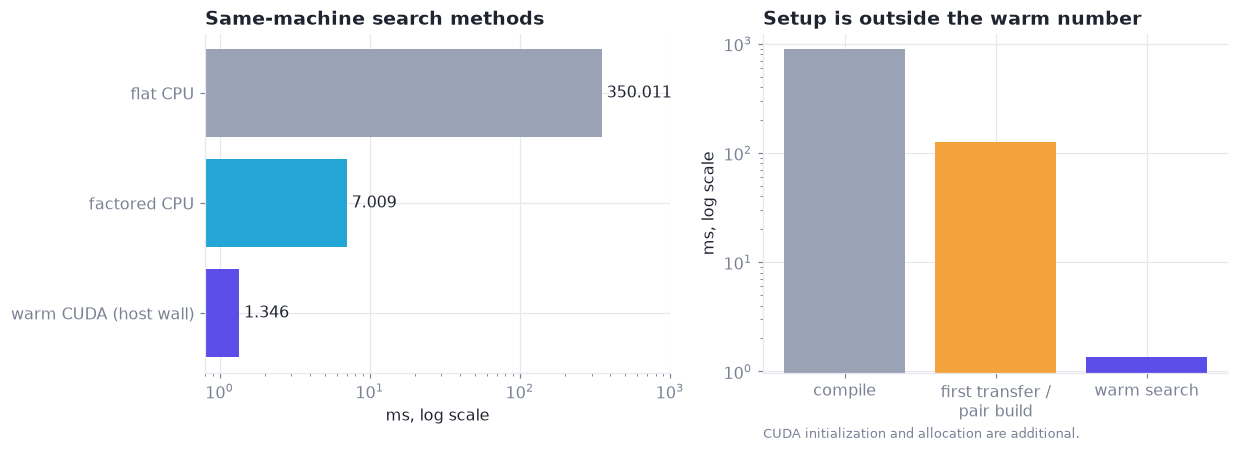

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
import json
search = json.loads((DATA / "decoder_search.json").read_text())
assert search["cpu_cuda_solution_sets_equal"] and search["legal_graphs"] == 1816
print(f"Exact coverage: {search['raw_combinations']:,} combinations -> {search['legal_graphs']:,} legal graphs")
methods = ["flat CPU", "factored CPU", "warm CUDA (host wall)"]
times = [search[k] for k in ["flat_cpu_ms", "factored_cpu_ms", "warm_gpu_wall_ms"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(methods[::-1], times[::-1], color=[C["ours"], C["cyan"], C["ref"]])
axes[0].set_xscale("log"); axes[0].set_xlabel("ms, log scale")
axes[0].set_title("Same-machine search methods")
for i, value in enumerate(times[::-1]): axes[0].text(value * 1.08, i, f"{value:.3f}", va="center")
axes[0].set_xlim(.8, 1000)
costs = [search["compile_ms"], search["first_transfer_and_pair_build_ms"], search["warm_gpu_wall_ms"]]
axes[1].bar(["compile", "first transfer /\npair build", "warm search"], costs,
            color=[C["ref"], C["accent"], C["ours"]])
axes[1].set_yscale("log"); axes[1].set_ylabel("ms, log scale")
axes[1].set_title("Setup is outside the warm number")
note(axes[1], "CUDA initialization and allocation are additional.")
save(fig, "structural_search_costs"); plt.show()


## Coverage includes failures and distinct implementation contexts

The ledger contains 36 ownership and 40 compute-family entries, including
repeated designs and failures. A missing latency is not zero. Early ownership
measurements retain their original context; a generator repair does not
retroactively change their values.

In [2]:
ledger = pd.read_csv(DATA / "structural_search.csv")
assert len(ledger) == 76
display(ledger.groupby(["family", "status"]).size().rename("entries").to_frame())
display(ledger[["family", "batch", "context", "compute", "activation", "status", "ratio"]])


entries
family    status                  
compute   compile_failure        5
          measured              31
          runtime_failure        4
ownership compile_failure        1
          measured              35

,family,batch,context,compute,activation,status,ratio
0,ownership,outer_campaign_01/round_001,cute_sassy.outer.v1,parent,parent,measured,0.915974
1,ownership,outer_campaign_01/round_001,cute_sassy.outer.v1,parent,parent,measured,0.712125
2,ownership,outer_campaign_01/round_001,cute_sassy.outer.v1,parent,parent,measured,0.839076
3,ownership,outer_campaign_01/round_001,cute_sassy.outer.v1,parent,parent,measured,0.905474
4,ownership,outer_campaign_01/round_001,cute_sassy.outer.v1,parent,parent,measured,0.956882
...,...,...,...,...,...,...,...
71,compute,program_campaign_02/round_002,program,sparse_d1,register,measured,0.988851
72,compute,program_campaign_02/round_002,program,dense,register,measured,0.929987
73,compute,program_campaign_02/round_002,program,dense,register,measured,1.000509
74,compute,program_campaign_02/round_002,program,hfma2_group_d1,register,measured,0.998716


## Corrected ownership campaign: values carry uncertainty

These are the recorded intervals for the corrected two-round ownership campaign.
The vertical line is parity with its frozen parent. They are complete six-load
ratios, not official scores.

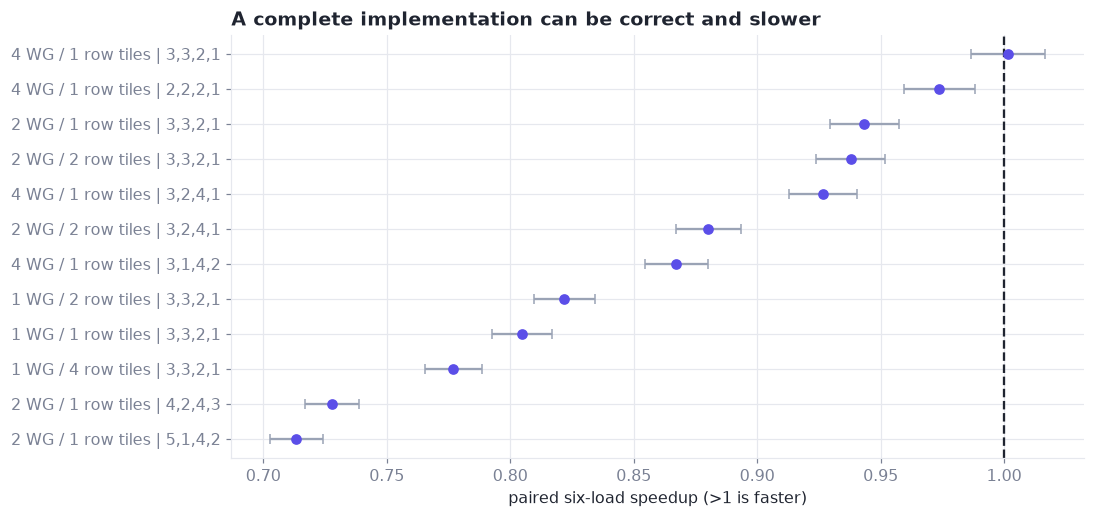

In [3]:
selected = ledger[(ledger.family == "ownership") &
                  ledger.batch.str.startswith("outer_campaign_v2/") &
                  ledger.status.eq("measured")].copy().sort_values("ratio")
assert len(selected) == 12
y = np.arange(len(selected))
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(selected.ratio, y,
    xerr=np.array([selected.ratio - selected.interval_low, selected.interval_high - selected.ratio]),
    fmt="o", color=C["ours"], ecolor=C["ref"], capsize=3)
ax.axvline(1, color=INK, ls="--")
ax.set_yticks(y, [f"{w} WG / {t} row tiles | {p}" for w,t,p in zip(selected.warpgroups, selected.row_tiles, selected.pipeline)])
ax.set_xlabel("paired six-load speedup (>1 is faster)")
ax.set_title("A complete implementation can be correct and slower")
save(fig, "structural_search_outcomes"); plt.show()


## Execute the finite-alphabet contracts

Unlike the production GPU search, this scalar constructor is shipped. It checks
every paired FP4/scale encoding and searches exact decompositions
$x=h+2^{-r}l$ with E4M3 components. Coverage is bounded by the exponent window;
it does not establish arbitrary BF16 matrix accumulation equivalence.

Paired finite/NaN-class cases: 65024 512


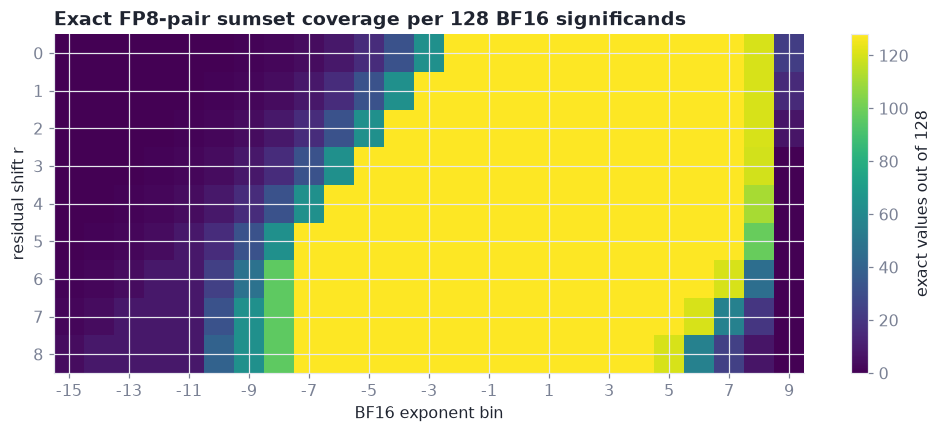

,residual_shift,high_method,scalar_cases,exponent_window
0,4,truncate_bf16_low4,3584,"[-6, 7]"
1,5,nearest_fp8,3840,"[-7, 7]"


In [4]:
from tempfile import TemporaryDirectory
sys.path.insert(0, str(ROOT / "examples"))
from finite_alphabet import lut_contract, fp8_contract
with TemporaryDirectory(prefix="finite-alphabet-") as temp:
    lut = lut_contract(Path(temp))
    components = fp8_contract(Path(temp))
assert lut["finite_pair_scale_cases"] == 65024 and lut["nan_pair_scale_cases"] == 512
print("Paired finite/NaN-class cases:", lut["finite_pair_scale_cases"], lut["nan_pair_scale_cases"])
coverage = np.array([[b["exact_of_128"] for b in row["binades"]] for row in components["coverage"]])
exponents = [b["exponent"] for b in components["coverage"][0]["binades"]]
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(coverage, aspect="auto", vmin=0, vmax=128, cmap="viridis")
ax.set_xticks(range(0, len(exponents), 2), exponents[::2])
ax.set_ylabel("residual shift r"); ax.set_xlabel("BF16 exponent bin")
ax.set_title("Exact FP8-pair sumset coverage per 128 BF16 significands")
fig.colorbar(im, ax=ax, label="exact values out of 128")
save(fig, "finite_alphabet_coverage"); plt.show()
display(pd.DataFrame(components["constructions"])[["residual_shift", "high_method", "scalar_cases", "exponent_window"]])


## Copy traces and whole-operator composition

All 168 copy-only patterns passed their byte checks. They omit MMA. The later
operator study has nine candidates/cells × six loads = 54 rows, using direct
launches and stream events. This is a different protocol from graph replay;
the figures below keep the two measurement scopes separate.

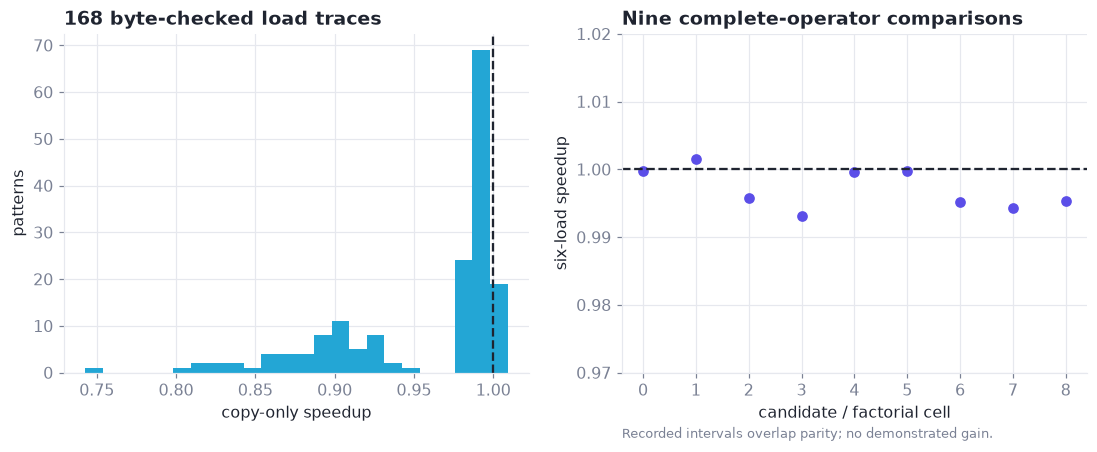

ratio  recorded
stage       design                              
composition 3882d38039285459  0.999697  0.999697
            6704ad4708c480b6  1.001569  1.001569
            7ec11152af0490e4  0.995714  0.995714
finalists   27ea397bf44ec753  0.993195  0.993195
            7ec11152af0490e4  0.999542  0.999542
            9fd97345483157e3  0.999722  0.999722
            a594a5f546aa1e8f  0.995242  0.995242
            df80fe56de44c182  0.994312  0.994312
            eb15400ec83b2b9c  0.995343  0.995343

In [5]:
patterns = pd.read_csv(DATA / "load_patterns.csv")
transport = pd.read_csv(DATA / "load_composition.csv")
assert len(patterns) == 168 and (patterns.bad_threads == 0).all()
assert len(transport) == 54
groups = transport.groupby(["stage", "design"])
assert groups.size().eq(6).all()
whole = groups.agg(ratio=("ratio", lambda x: np.exp(np.log(x).mean())), recorded=("all_load_ratio", "first"))
assert np.allclose(whole.ratio, whole.recorded)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(patterns.geomean_speedup, bins=24, color=C["cyan"])
axes[0].axvline(1, color=INK, ls="--"); axes[0].set_xlabel("copy-only speedup")
axes[0].set_ylabel("patterns"); axes[0].set_title("168 byte-checked load traces")
axes[1].scatter(np.arange(len(whole)), whole.ratio, color=C["ours"])
axes[1].axhline(1, color=INK, ls="--"); axes[1].set_xlabel("candidate / factorial cell")
axes[1].set_ylabel("six-load speedup"); axes[1].set_ylim(.97, 1.02)
axes[1].set_title("Nine complete-operator comparisons")
note(axes[1], "Recorded intervals overlap parity; no demonstrated gain.")
save(fig, "load_pattern_results"); plt.show()
display(whole)


## A separate deterministic campaign

This later batch used neither model inference nor MCTS. It compiled 44 complete plans, measured 28, and found no demonstrated gain. Do not combine it with the earlier ledger as one policy evaluation.

In [6]:
det = json.loads((DATA / "deterministic_search.json").read_text())
assert det["full_operator_candidates"] == det["qualified"] == 28
assert det["demonstrated_gains"] == 0 and not det["target_achieved"]
lo, hi = det["best_private_interval"]
assert lo < 1 < hi
print(f"Best paired ratio: {det['best_private_ratio']:.6f}, interval [{lo:.6f}, {hi:.6f}]")
print("The 2.7x target remains open; fast enumeration is a separate result.")


Best paired ratio: 1.000972, interval [0.986179, 1.015986]
The 2.7x target remains open; fast enumeration is a separate result.


[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)